# Van de Vusse NMPC - shrinking-horizon output surrogate and receding control

This notebook mirrors the control-surrogate workflow of notebook 04 for the smaller Van de Vusse CSTR benchmark. The true plant is the nonlinear isothermal reactor

```text
A -> B -> C,    2A -> D
```

with the dilution rate `D = F/V` as the manipulated input and `CB` as the desired product concentration.

## Problem definition

This notebook solves the **inverse-response operating-point transition problem** for the simplified four-concentration Van de Vusse model. The plant starts from the Set 1 inverse-response steady state, not from zero concentrations:

```text
x(0) = [CA, CB, CC, CD] = [3.0, 1.11702128, 3.25797872, 1.3125]
D_initial = 4/7 min^-1
```

The manipulated input is a piecewise-constant dilution-rate sequence `D_0, ..., D_99` with one move every `0.10 min = 6 s`, over a `10 min` horizon. The saved reference sequence was found by direct shooting on the true ODE to improve product concentration `CB` from this already-loaded reactor state, with a move penalty to discourage unnecessarily jumpy input changes.

Because the process has inverse response, a one-step maximization of `CB_{k+1}` can choose poor moves. The learning problem is therefore formulated as **shrinking-horizon output prediction**:

```text
[CA_k, CB_k, CC_k, CD_k, D_k, ..., D_{k+P-1}, horizon_frac]
    -> horizon_delta_CB_k = CB_{k+m} - CB_k,    m = min(P, H - k)
```

where `P` is the maximum prediction horizon and `m` is the number of active moves remaining to the fixed terminal step `H`, encoded as `horizon_frac = m / P` (unused control slots are held constant). The current concentrations are fixed measurements; the optimizer chooses only the future dilution-rate sequence. The receding controller maximizes predicted end-of-horizon `CB` minus a move penalty, applies only the first dilution-rate move to the true plant, then repeats from the new measured state. The horizon **shrinks** to the steps remaining as the run approaches `t = 10 min`, so near the end the surrogate predicts `CB` at the true terminal time rather than a constant `P` steps past it. Without this, a fixed `P`-step look-ahead has no terminal-time awareness and cannot reproduce the reference's end-loaded exit arc.

This simplified Van de Vusse benchmark has no pressure state or pressure constraint. Constraint handling here means respecting the dilution-rate bounds and checking the concentration state bounds. If a pressure variable is added later, it should be added as an additional prediction target and constraint output.

Scope for this benchmark:

- load the saved refined 6-second direct-shooting path from `datasets/vdv_refined_6sec_solution.npz`;
- build a shrinking-horizon `CB` training set (windows for every step `k = 0..H-1`, horizon `m = min(P, H - k)`) from the optimal trajectory plus local state/control-sequence perturbations;
- train tanh, ReLU, and PWL-tanh-compatible horizon-aware output surrogates;
- run receding closed-loop control by maximizing predicted end-of-horizon `CB` over bounded candidate dilution-rate sequences, shrinking the horizon near the terminal time;
- compare the closed-loop true-plant trajectories against the saved refined path.

No multiple-shooting benchmark is included here.


## Setup

In [85]:
from __future__ import annotations

from pathlib import Path
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "pyproject.toml").exists() and (candidate / "src" / "pwlnet").exists():
        ROOT = candidate
        break
if ROOT is None:
    raise RuntimeError("Could not find the PWLNet project root from the notebook working directory.")

src = ROOT / "src"
if str(src) not in sys.path:
    sys.path.insert(0, str(src))

from pwlnet import PWLNet
from pwlnet.formulations.pyomo_pwl import evaluate_tanh_pwl_network
from pwlnet.processes.van_de_vusse import (
    CONTROL_BOUNDS,
    DECISION_DT_MIN,
    OPERATING_POINT_1,
    OUTPUT_NAMES,
    STATE_BOUNDS,
    STATE_NAMES,
    VanDeVusseParameters,
    find_max_product_dilution,
    simulate_policy,
    solve_steady_state,
    step_state,
)

RANDOM_SEED = 2479085
rng = np.random.default_rng(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid")

CB_IDX = OUTPUT_NAMES.index("CB")
D_LO, D_HI = CONTROL_BOUNDS[0]
N_STATE = len(STATE_NAMES)

# ``PREDICTION_HORIZON_STEPS`` is the *maximum* look-ahead P. The surrogate is made
# horizon-aware: it predicts the change in CB after only the first ``m`` of the P
# control slots, with ``m`` encoded by an extra normalized feature
# ``horizon_frac = m / P``. The receding controller then *shrinks* its horizon as it
# nears the fixed terminal time so it optimizes the true end-of-horizon CB instead of
# always looking a constant P steps past it.
PREDICTION_HORIZON_STEPS = 10
CONTROL_FEATURE_NAMES = [f"D_t+{j}" for j in range(PREDICTION_HORIZON_STEPS)]
HORIZON_FEATURE_NAME = "horizon_frac"
FEATURE_NAMES = [*STATE_NAMES, *CONTROL_FEATURE_NAMES, HORIZON_FEATURE_NAME]
CONTROL_SLICE = slice(N_STATE, N_STATE + PREDICTION_HORIZON_STEPS)
HORIZON_COL = N_STATE + PREDICTION_HORIZON_STEPS
TARGET_NAME = "horizon_delta_CB"
print(f"inputs: [{', '.join(FEATURE_NAMES)}], output: {TARGET_NAME}")


inputs: [CA, CB, CC, CD, D_t+0, D_t+1, D_t+2, D_t+3, D_t+4, D_t+5, D_t+6, D_t+7, D_t+8, D_t+9, horizon_frac], output: horizon_delta_CB


## Refined 6-second reference path

The reference path was computed by coarse-to-fine direct shooting on the true ODE and then refined on the default Van de Vusse control grid. The final profile is piecewise constant with `dt = 0.10 min = 6 s`, so it matches the default control problem. It is not a surrogate solution.

The concentration initial condition is the inverse-response Set 1 operating point, represented in this simplified model as the steady state at `D = 4/7 min^-1`. This makes the benchmark a transition/control problem from an already loaded reactor, not a zero-concentration startup.


In [86]:
OPT_PATH = ROOT / "datasets" / "vdv_refined_6sec_solution.npz"
if not OPT_PATH.exists():
    raise FileNotFoundError(
        f"Missing {OPT_PATH}. Run experiments/van_de_vusse/refine_default_control_sequence.py first."
    )

opt = np.load(OPT_PATH, allow_pickle=False)
D_star = opt["D"].astype(float)
opt_states = opt["states"].astype(float)
opt_times = opt["times"].astype(float)
DT = float(opt["dt_min"])
H = len(D_star)
x0 = opt_states[0].copy()
REFERENCE_LABEL = "refined 6-second inverse-response path"
INITIAL_CONDITION_LABEL = "Set 1 inverse-response steady state"
expected_x0 = solve_steady_state(OPERATING_POINT_1["D"]).x

if not np.isclose(DT, DECISION_DT_MIN):
    warnings.warn(
        f"Loaded reference uses dt={DT:g} min, while DECISION_DT_MIN={DECISION_DT_MIN:g} min."
    )
if not np.allclose(x0, expected_x0, atol=1e-8):
    warnings.warn(f"Expected Set 1 inverse-response initial state {expected_x0}, got {x0}.")

ss = find_max_product_dilution()
summary = pd.DataFrame([
    {
        "case": "steady-state CB optimum",
        "initial state": "steady state",
        "D": ss.dilution_rate,
        "dt [s]": np.nan,
        "moves": np.nan,
        "terminal CB": ss.cb,
        "integral CB": np.nan,
    },
    {
        "case": REFERENCE_LABEL,
        "initial state": INITIAL_CONDITION_LABEL,
        "D": np.nan,
        "dt [s]": 60.0 * DT,
        "moves": H,
        "terminal CB": opt_states[-1, CB_IDX],
        "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    },
])
display(summary.round(6))
pd.DataFrame({"time [min]": opt_times[:-1], "D*": D_star})


,case,initial state,D,dt [s],moves,terminal CB,integral CB
0,steady-state CB optimum,steady state,1.292092,NaN,NaN,1.265986,NaN
1,refined 6-second inverse-response path,Set 1 inverse-response steady state,NaN,6.0,100.0,1.614158,12.377319


,time [min],D*
0,0.0,1.654673
1,0.1,1.787976
2,0.2,1.865734
3,0.3,1.888021
4,0.4,1.819536
...,...,...
95,9.5,0.463193
96,9.6,0.100000
97,9.7,0.100000
98,9.8,0.100000


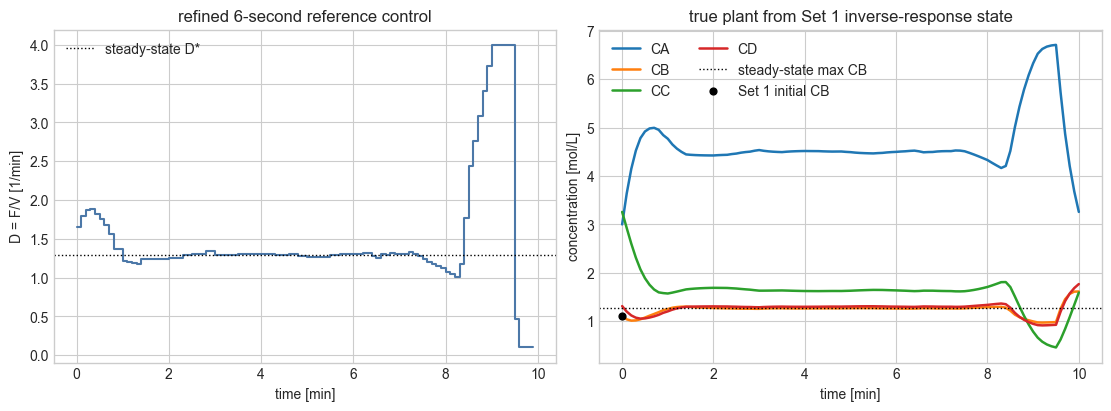

In [87]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
ax[0].step(opt_times[:-1], D_star, where="post", color="#4c78a8")
ax[0].axhline(ss.dilution_rate, color="black", ls=":", lw=1, label="steady-state D*")
ax[0].set(xlabel="time [min]", ylabel="D = F/V [1/min]", title="refined 6-second reference control")
ax[0].legend(frameon=False)

for i, name in enumerate(OUTPUT_NAMES):
    ax[1].plot(opt_times, opt_states[:, i], lw=1.8, label=name)
ax[1].axhline(ss.cb, color="black", ls=":", lw=1, label="steady-state max CB")
ax[1].scatter([opt_times[0]], [opt_states[0, CB_IDX]], color="black", s=24, zorder=4, label="Set 1 initial CB")
ax[1].set(xlabel="time [min]", ylabel="concentration [mol/L]", title="true plant from Set 1 inverse-response state")
ax[1].legend(frameon=False, ncol=2)
plt.show()


## Shrinking-horizon `CB` dataset around the refined path

The base samples are windows on the refined trajectory. Each row fixes the current concentrations, appends up to `P` dilution-rate moves plus the `horizon_frac` feature, and targets the change in the desired compound over the active horizon, `CB_{k+m} - CB_k`. Crucially the window loop now runs to `k = H - 1` with `m = min(P, H - k)`, so the **terminal exit arc is covered for every step** -- the previous fixed-horizon dataset stopped at `k = H - P`, leaving the last `P - 1` steps (and the end-of-horizon `CB` spike) essentially unseen, which is why the old controller could not reproduce the terminal move. The notebook then builds a local cloud around each window by perturbing the initial concentrations and the candidate control sequence, clipping to feasible bounds, and simulating the true plant over the active horizon; a few extra random-horizon samples per window exercise `horizon_frac` across the whole trajectory.


In [88]:
def pad_control_window(profile, start, horizon_steps):
    window = np.asarray(profile[start:start + horizon_steps], dtype=float)
    if len(window) < horizon_steps:
        fill = window[-1] if len(window) else profile[-1]
        window = np.r_[window, np.full(horizon_steps - len(window), fill)]
    return window


def hold_to_length(active_moves, length):
    """Zero-order-hold an active control sub-sequence up to ``length`` slots.

    Beyond the active moves the last value is repeated so the unused tail is a benign
    constant (the same convention used at training and control time), which the
    ``horizon_frac`` feature tells the network to ignore.
    """
    active = np.asarray(active_moves, dtype=float)
    if len(active) >= length:
        return active[:length].copy()
    fill = active[-1] if len(active) else 0.0
    return np.r_[active, np.full(length - len(active), fill)]


def simulate_horizon_delta_cb(state, active_moves):
    """Apply only the ``len(active_moves)`` active moves and return ``CB_end - CB_now``."""
    x = np.asarray(state, dtype=float).copy()
    for d in np.asarray(active_moves, dtype=float):
        x = step_state(x, float(d), dt_min=DT, n_substeps=12)
    return float(x[CB_IDX] - state[CB_IDX]), x


def make_terminal_cb_dataset(
    n_local_per_window=18,
    n_horizon_aug=6,
    state_scales=(0.12, 0.06, 0.16, 0.14),
    control_scale=0.18,
    control_walk_scale=0.08,
):
    rows_x, rows_y, rows_meta = [], [], []
    state_scales = np.asarray(state_scales, dtype=float)

    for k in range(H):
        # Steps remaining from k to the fixed terminal time, capped at the maximum P.
        m_full = min(PREDICTION_HORIZON_STEPS, H - k)
        x_ref = np.asarray(opt_states[k], dtype=float)

        # Unperturbed reference window at the full remaining horizon. Because the loop
        # now runs to k = H - 1 (not H - P), the terminal exit arc -- including the
        # end-of-horizon CB spike -- is represented for every step instead of only the
        # single k = H - P window that the previous fixed-horizon dataset contained.
        d_ref_active = D_star[k:k + m_full]
        terminal_delta_ref = float(opt_states[k + m_full, CB_IDX] - opt_states[k, CB_IDX])
        rows_x.append(np.r_[x_ref, hold_to_length(d_ref_active, PREDICTION_HORIZON_STEPS), m_full / PREDICTION_HORIZON_STEPS])
        rows_y.append([terminal_delta_ref])
        rows_meta.append({"source": "reference", "time": opt_times[k], "step": k, "horizon": m_full})

        # Local cloud: n_local_per_window samples at the horizon the controller will
        # actually use at step k, plus n_horizon_aug samples at random shorter horizons
        # so ``horizon_frac`` is exercised densely across the whole trajectory.
        horizons = [m_full] * n_local_per_window
        horizons += [int(rng.integers(1, m_full + 1)) for _ in range(n_horizon_aug)]
        for m in horizons:
            x0_local = x_ref + rng.normal(0.0, state_scales)
            x0_local = np.clip(x0_local, STATE_BOUNDS[:, 0], STATE_BOUNDS[:, 1])
            d_noise = rng.normal(0.0, control_scale, size=m)
            d_noise += np.cumsum(rng.normal(0.0, control_walk_scale, size=m))
            d_active = np.clip(D_star[k:k + m] + d_noise, D_LO, D_HI)
            terminal_delta_cb, _ = simulate_horizon_delta_cb(x0_local, d_active)
            rows_x.append(np.r_[x0_local, hold_to_length(d_active, PREDICTION_HORIZON_STEPS), m / PREDICTION_HORIZON_STEPS])
            rows_y.append([terminal_delta_cb])
            rows_meta.append({"source": "local perturbation", "time": opt_times[k], "step": k, "horizon": m})

    X = np.asarray(rows_x, dtype=float)
    Y = np.asarray(rows_y, dtype=float)
    meta = pd.DataFrame(rows_meta)
    return X, Y, meta


t0 = time.perf_counter()
X, Y, sample_meta = make_terminal_cb_dataset()
gen_seconds = time.perf_counter() - t0

perm = rng.permutation(len(X))
n_train = int(0.70 * len(perm))
n_val = int(0.15 * len(perm))
train_idx = perm[:n_train]
val_idx = perm[n_train:n_train + n_val]
test_idx = perm[n_train + n_val:]

X_train, Y_train = X[train_idx], Y[train_idx]
X_val, Y_val = X[val_idx], Y[val_idx]
X_test, Y_test = X[test_idx], Y[test_idx]

print(
    f"generated {len(X)} horizon-CB samples from {H} shrinking-horizon windows "
    f"(k = 0..{H - 1}) in {gen_seconds:.2f}s"
)
print(
    f"max prediction horizon P = {PREDICTION_HORIZON_STEPS} steps = "
    f"{PREDICTION_HORIZON_STEPS * DT:.2f} min; terminal windows shrink down to 1 step"
)
print(f"train={X_train.shape}, validation={X_val.shape}, test={X_test.shape}")
summary = pd.DataFrame(X, columns=FEATURE_NAMES).describe().T
summary.loc[TARGET_NAME, :] = np.nan
summary.loc[TARGET_NAME, ["mean", "std", "min", "max"]] = [Y.mean(), Y.std(), Y.min(), Y.max()]
display(summary.round(6))


generated 2500 horizon-CB samples from 100 shrinking-horizon windows (k = 0..99) in 6.17s
max prediction horizon P = 10 steps = 1.00 min; terminal windows shrink down to 1 step
train=(1750, 15), validation=(375, 15), test=(375, 15)


,count,mean,std,min,25%,50%,75%,max
CA,2500.0,4.650833,0.613546,2.802952,4.397526,4.508665,4.650126,6.985393
CB,2500.0,1.235804,0.123022,0.849960,1.188662,1.257930,1.302163,1.704860
CC,2500.0,1.588554,0.423879,0.141071,1.480558,1.623690,1.750607,3.718837
CD,2500.0,1.258738,0.187620,0.528527,1.150961,1.281970,1.378457,1.937654
D_t+0,2500.0,1.484847,0.769798,0.100000,1.157697,1.309324,1.521137,4.000000
D_t+1,2500.0,1.474358,0.777744,0.100000,1.139496,1.322714,1.540424,4.000000
D_t+2,2500.0,1.457503,0.791908,0.100000,1.124489,1.310170,1.531926,4.000000
D_t+3,2500.0,1.445945,0.803449,0.100000,1.094811,1.302812,1.549374,4.000000
D_t+4,2500.0,1.430833,0.819188,0.100000,1.072930,1.294154,1.544827,4.000000
D_t+5,2500.0,1.419411,0.826995,0.100000,1.060991,1.297424,1.549624,4.000000


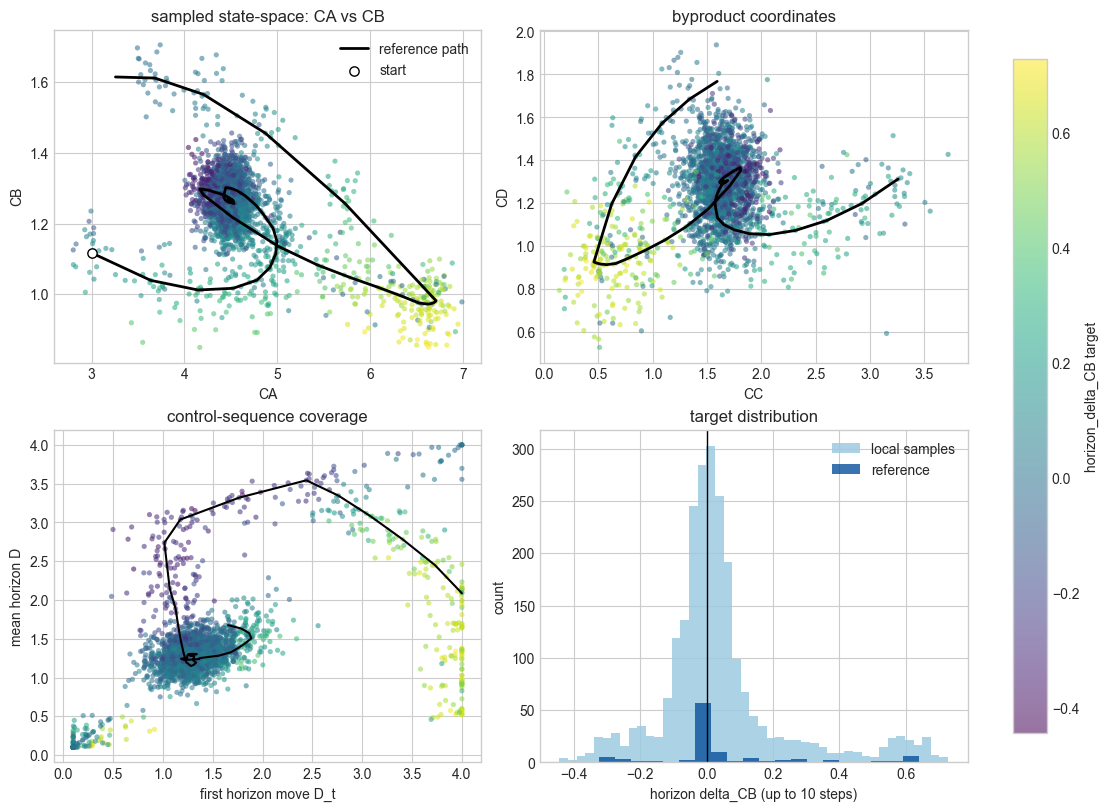

In [89]:
plot_df = pd.DataFrame(X[:, :N_STATE], columns=STATE_NAMES)
plot_df["D_first"] = X[:, N_STATE]
plot_df["D_mean"] = X[:, CONTROL_SLICE].mean(axis=1)
plot_df[TARGET_NAME] = Y[:, 0]
plot_df["source"] = sample_meta["source"].to_numpy()

fig, ax = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
scatter_kwargs = dict(c=plot_df[TARGET_NAME], cmap="viridis", s=14, alpha=0.55, linewidths=0)

sc = ax[0, 0].scatter(plot_df["CA"], plot_df["CB"], **scatter_kwargs)
ax[0, 0].plot(opt_states[:, 0], opt_states[:, 1], color="black", lw=2, label="reference path")
ax[0, 0].scatter(opt_states[0, 0], opt_states[0, 1], color="white", edgecolor="black", s=45, zorder=3, label="start")
ax[0, 0].set(xlabel="CA", ylabel="CB", title="sampled state-space: CA vs CB")
ax[0, 0].legend(frameon=False)

ax[0, 1].scatter(plot_df["CC"], plot_df["CD"], **scatter_kwargs)
ax[0, 1].plot(opt_states[:, 2], opt_states[:, 3], color="black", lw=2)
ax[0, 1].set(xlabel="CC", ylabel="CD", title="byproduct coordinates")

ax[1, 0].scatter(plot_df["D_first"], plot_df["D_mean"], **scatter_kwargs)
ax[1, 0].plot(D_star[:-PREDICTION_HORIZON_STEPS + 1], [
    pad_control_window(D_star, k, PREDICTION_HORIZON_STEPS).mean()
    for k in range(H - PREDICTION_HORIZON_STEPS + 1)
], color="black", lw=1.5)
ax[1, 0].set(xlabel="first horizon move D_t", ylabel="mean horizon D", title="control-sequence coverage")

is_ref = plot_df["source"].eq("reference")
ax[1, 1].hist(plot_df.loc[~is_ref, TARGET_NAME], bins=45, color="#9ecae1", alpha=0.85, label="local samples")
ax[1, 1].hist(plot_df.loc[is_ref, TARGET_NAME], bins=20, color="#08519c", alpha=0.80, label="reference")
ax[1, 1].axvline(0.0, color="black", lw=1)
ax[1, 1].set(xlabel=f"horizon delta_CB (up to {PREDICTION_HORIZON_STEPS} steps)", ylabel="count", title="target distribution")
ax[1, 1].legend(frameon=False)

cbar = fig.colorbar(sc, ax=ax[:, :], shrink=0.92)
cbar.set_label("horizon_delta_CB target")
plt.show()


## Train horizon-aware output surrogates

The networks learn the change in the desired compound over a *variable* prediction horizon: the input carries the `P` dilution-rate slots plus a normalized `horizon_frac = m / P` feature, and the target is `CB_{k+m} - CB_k` for the first `m` active moves (the unused tail slots are held constant). During receding control the predicted product concentration is reconstructed as `CB_k + horizon_delta_CB_hat`, where `m` shrinks to the steps remaining as `t -> 10 min`. The PWL-tanh version is still evaluated from the same tanh network with a piecewise-linear activation approximation.


In [90]:
COMMON_TRAIN = dict(
    epochs=450,
    batch_size=96,
    validation_split=0.0,
    verbose=0,
    random_seed=RANDOM_SEED,
)

MODEL_SPECS = {
    "tanh smooth": dict(hidden_layers=[24, 16], activation="tanh"),
    "ReLU": dict(hidden_layers=[24, 16], activation="relu"),
}

t0 = time.perf_counter()
tanh_net = PWLNet.train(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    **MODEL_SPECS["tanh smooth"],
    **COMMON_TRAIN,
)
tanh_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
relu_net = PWLNet.train(
    X_train, Y_train,
    validation_data=(X_val, Y_val),
    **MODEL_SPECS["ReLU"],
    **COMMON_TRAIN,
)
relu_seconds = time.perf_counter() - t0

print(f"tanh training: {tanh_seconds:.2f}s")
print(f"ReLU training: {relu_seconds:.2f}s")


tanh training: 35.59s
ReLU training: 34.10s


## Terminal-horizon `CB` prediction accuracy


In [91]:
BP = 5
predictions = {
    "tanh smooth": tanh_net.predict(X_test),
    "ReLU": relu_net.predict(X_test),
    "tanh PWL-5": evaluate_tanh_pwl_network(tanh_net.network, X_test, breakpoints=BP),
}

rows = []
y_true = Y_test[:, 0]
for label, pred in predictions.items():
    y_pred = np.asarray(pred, dtype=float).reshape(-1)
    err = y_pred - y_true
    denom = np.sum((y_true - y_true.mean()) ** 2)
    rows.append({
        "model": label,
        "target": TARGET_NAME,
        "MAE": np.mean(np.abs(err)),
        "RMSE": np.sqrt(np.mean(err ** 2)),
        "max abs error": np.max(np.abs(err)),
        "R2": 1.0 - np.sum(err ** 2) / denom if denom > 0 else np.nan,
    })
metrics = pd.DataFrame(rows)
display(metrics.round(6))


,model,target,MAE,RMSE,max abs error,R2
0,tanh smooth,horizon_delta_CB,0.006361,0.010113,0.060517,0.997759
1,ReLU,horizon_delta_CB,0.007381,0.012415,0.079526,0.996623
2,tanh PWL-5,horizon_delta_CB,0.043639,0.050987,0.156446,0.943037


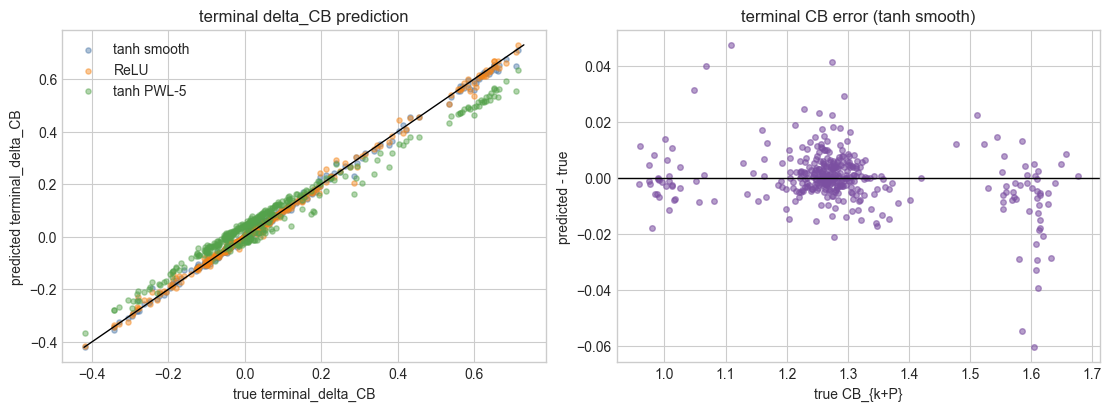

In [92]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
colors = {"tanh smooth": "#4c78a8", "ReLU": "#f58518", "tanh PWL-5": "#54a24b"}

for label, pred in predictions.items():
    y_pred = np.asarray(pred, dtype=float).reshape(-1)
    ax[0].scatter(y_true, y_pred, s=14, alpha=0.45, label=label, color=colors.get(label))
lo = min(y_true.min(), *(np.asarray(p).reshape(-1).min() for p in predictions.values()))
hi = max(y_true.max(), *(np.asarray(p).reshape(-1).max() for p in predictions.values()))
ax[0].plot([lo, hi], [lo, hi], color="black", lw=1)
ax[0].set(title="terminal delta_CB prediction", xlabel="true terminal_delta_CB", ylabel="predicted terminal_delta_CB")
ax[0].legend(frameon=False)

best_label = metrics.sort_values("RMSE").iloc[0]["model"]
best_pred = np.asarray(predictions[best_label], dtype=float).reshape(-1)
terminal_cb_true = X_test[:, CB_IDX] + y_true
terminal_cb_pred = X_test[:, CB_IDX] + best_pred
err = terminal_cb_pred - terminal_cb_true
ax[1].scatter(terminal_cb_true, err, s=16, alpha=0.55, color="#7b4fa1")
ax[1].axhline(0.0, color="black", lw=1)
ax[1].set(title=f"terminal CB error ({best_label})", xlabel="true CB_{k+P}", ylabel="predicted - true")
plt.show()


## Receding shrinking-horizon control

At each 6-second move, the current measured concentration state is fixed as an equality constraint and the controller optimizes only a candidate sequence of future dilution rates. The score is predicted end-of-horizon `CB` minus a move penalty; only the first move is applied to the true plant before the problem is rebuilt at the next measured state.

The horizon now **shrinks** as the run approaches the fixed terminal time `t = 10 min`. At step `k` the controller uses `m = min(P, H - k)` active moves and sets `horizon_frac = m / P`, so for the last `P` steps the surrogate predicts `CB` at the *true* terminal step instead of a constant `P` steps beyond it. This is the fix for the previous failure mode: with a fixed `P`-step look-ahead the controller never "saw the clock running out", so near the end it kept `D` pinned high and skipped the optimal terminal exit arc -- the brief `D -> D_min` crash that lets accumulated reactant convert into the end-of-horizon `CB` spike. With the shrinking horizon, and with the training set now covering those terminal windows, the controller commits to the exit arc and recovers a terminal `CB` close to the refined reference.

The reformulation still handles inverse response: a move can be accepted even if it hurts the immediate next `CB`, as long as it improves the (now correctly-timed) end-of-horizon prediction.


In [93]:
def predict_terminal_delta_cb(label, X_eval):
    if label == "tanh smooth":
        return tanh_net.predict(X_eval).reshape(-1)
    if label == "ReLU":
        return relu_net.predict(X_eval).reshape(-1)
    if label == "tanh PWL-5":
        return evaluate_tanh_pwl_network(tanh_net.network, X_eval, breakpoints=BP).reshape(-1)
    raise KeyError(label)


def max_state_bound_violation(states):
    states = np.asarray(states, dtype=float)
    low = np.maximum(STATE_BOUNDS[:, 0] - states, 0.0)
    high = np.maximum(states - STATE_BOUNDS[:, 1], 0.0)
    return float(np.max(np.maximum(low, high)))


def fixed_state_sequence_rows(current_state, control_sequences, horizon_frac):
    """Build surrogate inputs: fixed measured state, varying D sequence, horizon feature."""
    current_state = np.asarray(current_state, dtype=float).reshape(N_STATE)
    control_sequences = np.asarray(control_sequences, dtype=float)
    candidate_rows = np.column_stack([
        np.repeat(current_state[None, :], len(control_sequences), axis=0),
        control_sequences,
        np.full((len(control_sequences), 1), float(horizon_frac)),
    ])
    fixed_state_error = float(np.max(np.abs(candidate_rows[:, :N_STATE] - current_state)))
    if fixed_state_error > 1e-12:
        raise RuntimeError("Terminal-horizon candidate rows changed the measured state columns.")
    return candidate_rows, fixed_state_error


def candidate_control_sequences(step_index, d_prev, horizon, candidate_count=800):
    """Candidates for the ``horizon`` active moves, zero-order-held to the P input slots."""
    m = int(horizon)
    start = min(step_index, H - 1)
    ref_active = hold_to_length(D_star[start:start + m], m)
    sequences = [
        hold_to_length(ref_active, PREDICTION_HORIZON_STEPS),
        hold_to_length(np.full(m, d_prev), PREDICTION_HORIZON_STEPS),
        hold_to_length(np.linspace(d_prev, ref_active[-1], m), PREDICTION_HORIZON_STEPS),
    ]
    random_count = max(0, int(candidate_count) - len(sequences))
    for _ in range(random_count):
        noise = rng.normal(0.0, 0.24, size=m)
        noise += np.cumsum(rng.normal(0.0, 0.08, size=m))
        seq = np.clip(ref_active + noise, D_LO, D_HI)
        seq[0] = np.clip(0.70 * seq[0] + 0.30 * d_prev, D_LO, D_HI)
        sequences.append(hold_to_length(seq, PREDICTION_HORIZON_STEPS))
    return np.asarray(sequences, dtype=float)


def run_terminal_horizon_control(label, *, move_penalty=0.001, candidate_count=800):
    states = [x0.copy()]
    controls = []
    predicted_terminal_cb = []
    scores = []
    horizons = []
    fixed_state_errors = []
    d_prev = float(OPERATING_POINT_1["D"])

    for k in range(H):
        x_curr = states[-1]
        # Shrinking horizon: never look past the fixed terminal time t = H * dt. For the
        # last P steps m = H - k < P, so the surrogate predicts CB at the *true* terminal
        # step rather than P steps beyond it -- this is what lets the controller commit to
        # the end-of-horizon exit arc instead of holding D high through the finish.
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        horizon_frac = m / PREDICTION_HORIZON_STEPS
        control_sequences = candidate_control_sequences(k, d_prev, m, candidate_count=candidate_count)
        X_eval, fixed_state_error = fixed_state_sequence_rows(x_curr, control_sequences, horizon_frac)
        terminal_delta_cb = predict_terminal_delta_cb(label, X_eval)
        terminal_cb = x_curr[CB_IDX] + terminal_delta_cb
        active = control_sequences[:, :m]
        diffs = np.diff(np.column_stack([np.full(len(active), d_prev), active]), axis=1)
        move_cost = np.sum(np.abs(diffs), axis=1)
        score = terminal_cb - float(move_penalty) * move_cost
        best = int(np.argmax(score))
        d = float(control_sequences[best, 0])
        x_next = step_state(x_curr, d, dt_min=DT, n_substeps=12)
        states.append(x_next)
        controls.append(d)
        predicted_terminal_cb.append(float(terminal_cb[best]))
        scores.append(float(score[best]))
        horizons.append(int(m))
        fixed_state_errors.append(fixed_state_error)
        d_prev = d

    states = np.asarray(states)
    controls = np.asarray(controls)
    times = np.arange(len(states)) * DT
    control_times = times[:-1]
    return {
        "status": "ok",
        "times": times,
        "control_times": control_times,
        "states": states,
        "controls": controls,
        "predicted_terminal_CB": np.asarray(predicted_terminal_cb),
        "scores": np.asarray(scores),
        "horizons": np.asarray(horizons),
        "prediction_horizon_steps": PREDICTION_HORIZON_STEPS,
        "move_penalty": float(move_penalty),
        "fixed_state_error": float(np.max(fixed_state_errors)),
        "state_bound_violation": max_state_bound_violation(states),
    }


RECEDING_MODELS = ["tanh smooth", "ReLU", "tanh PWL-5"]
t0 = time.perf_counter()
receding_runs = {
    label: run_terminal_horizon_control(label, move_penalty=0.001)
    for label in RECEDING_MODELS
}
receding_seconds = time.perf_counter() - t0
print(f"ran {len(receding_runs)} shrinking-horizon controllers in {receding_seconds:.2f}s")
receding_runs


ran 3 shrinking-horizon controllers in 3.47s


{'tanh smooth': {'status': 'ok',
  'times': array([ 0. ,  0.1,  0.2,  0.3,  0.4,  0.5,  0.6,  0.7,  0.8,  0.9,  1. ,
          1.1,  1.2,  1.3,  1.4,  1.5,  1.6,  1.7,  1.8,  1.9,  2. ,  2.1,
          2.2,  2.3,  2.4,  2.5,  2.6,  2.7,  2.8,  2.9,  3. ,  3.1,  3.2,
          3.3,  3.4,  3.5,  3.6,  3.7,  3.8,  3.9,  4. ,  4.1,  4.2,  4.3,
          4.4,  4.5,  4.6,  4.7,  4.8,  4.9,  5. ,  5.1,  5.2,  5.3,  5.4,
          5.5,  5.6,  5.7,  5.8,  5.9,  6. ,  6.1,  6.2,  6.3,  6.4,  6.5,
          6.6,  6.7,  6.8,  6.9,  7. ,  7.1,  7.2,  7.3,  7.4,  7.5,  7.6,
          7.7,  7.8,  7.9,  8. ,  8.1,  8.2,  8.3,  8.4,  8.5,  8.6,  8.7,
          8.8,  8.9,  9. ,  9.1,  9.2,  9.3,  9.4,  9.5,  9.6,  9.7,  9.8,
          9.9, 10. ]),
  'control_times': array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. , 1.1, 1.2,
         1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2, 2.3, 2.4, 2.5,
         2.6, 2.7, 2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5, 3.6, 3.7, 3.8,
         3.9, 4. , 4.

In [94]:
rows = []
for label, run in receding_runs.items():
    states = run["states"]
    controls = run["controls"]
    rows.append({
        "controller": label,
        "status": run["status"],
        "terminal CB": states[-1, CB_IDX],
        "integral CB": np.trapezoid(states[:, CB_IDX], x=run["times"]),
        "D min": np.min(controls),
        "D max": np.max(controls),
        "max |delta D|": np.max(np.abs(np.diff(np.r_[OPERATING_POINT_1["D"], controls]))),
        "prediction horizon [steps]": run["prediction_horizon_steps"],
        "max fixed-state error": run["fixed_state_error"],
        "state bound violation": run["state_bound_violation"],
    })
rows.append({
    "controller": "refined direct-shooting reference",
    "status": "reference",
    "terminal CB": opt_states[-1, CB_IDX],
    "integral CB": np.trapezoid(opt_states[:, CB_IDX], x=opt_times),
    "D min": float(np.min(D_star)),
    "D max": float(np.max(D_star)),
    "max |delta D|": float(np.max(np.abs(np.diff(np.r_[OPERATING_POINT_1["D"], D_star])))),
    "prediction horizon [steps]": PREDICTION_HORIZON_STEPS,
    "max fixed-state error": 0.0,
    "state bound violation": max_state_bound_violation(opt_states),
})
results_table = pd.DataFrame(rows)
display(results_table.round(6))


,controller,status,terminal CB,integral CB,D min,D max,max |delta D|,prediction horizon [steps],max fixed-state error,state bound violation
0,tanh smooth,ok,1.609610,12.404966,0.1,3.963601,2.704521,10,0.0,0.0
1,ReLU,ok,1.601668,12.392101,0.1,3.948669,2.195847,10,0.0,0.0
2,tanh PWL-5,ok,1.609927,12.390740,0.1,3.988596,2.519226,10,0.0,0.0
3,refined direct-shooting reference,reference,1.614158,12.377319,0.1,4.000000,3.536807,10,0.0,0.0


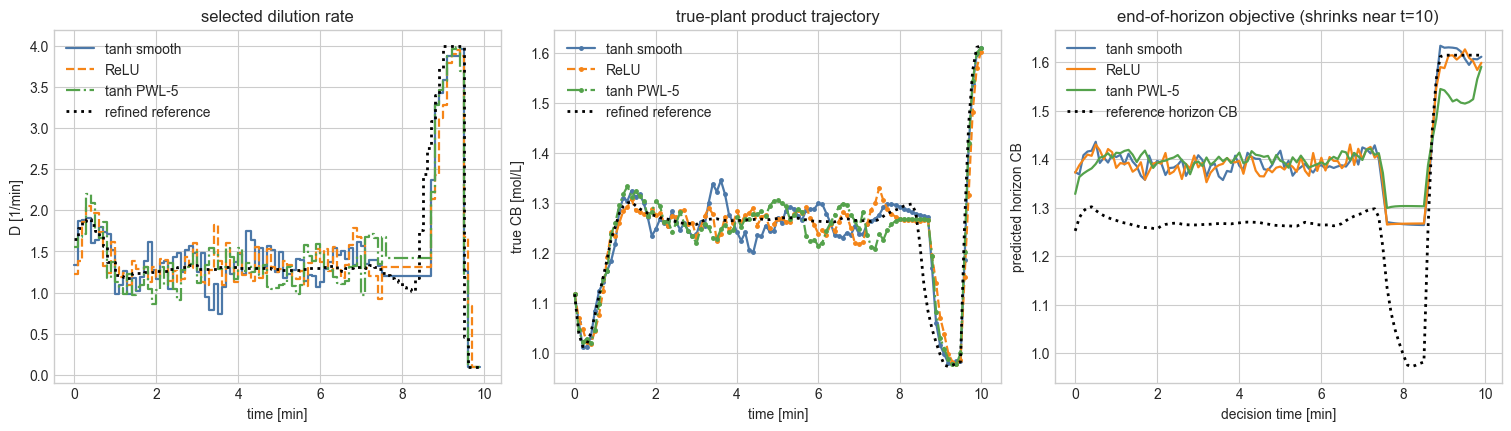

In [95]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), constrained_layout=True)
colors = {"tanh smooth": "#4c78a8", "ReLU": "#f58518", "tanh PWL-5": "#54a24b"}
styles = {"tanh smooth": "-", "ReLU": "--", "tanh PWL-5": "-."}
for label, run in receding_runs.items():
    ax[0].step(run["control_times"], run["controls"], where="post", label=label, color=colors.get(label), linestyle=styles.get(label), lw=1.6)
    ax[1].plot(run["times"], run["states"][:, CB_IDX], marker="o", ms=2.5, label=label, color=colors.get(label), linestyle=styles.get(label), lw=1.6)
    ax[2].plot(run["control_times"], run["predicted_terminal_CB"], lw=1.6, label=label, color=colors.get(label))

# Reference end-of-horizon target, shrinking to the fixed terminal time over the last P steps.
ref_horizon_cb = np.array([opt_states[min(k + PREDICTION_HORIZON_STEPS, H), CB_IDX] for k in range(H)])
ax[0].step(opt_times[:-1], D_star, where="post", color="black", ls=":", lw=2, label="refined reference")
ax[1].plot(opt_times, opt_states[:, CB_IDX], color="black", ls=":", lw=2, label="refined reference")
ax[2].plot(opt_times[:-1], ref_horizon_cb, color="black", ls=":", lw=2, label="reference horizon CB")
ax[0].set(xlabel="time [min]", ylabel="D [1/min]", title="selected dilution rate")
ax[1].set(xlabel="time [min]", ylabel="true CB [mol/L]", title="true-plant product trajectory")
ax[2].set(xlabel="decision time [min]", ylabel="predicted horizon CB", title="end-of-horizon objective (shrinks near t=10)")
for axis in ax:
    axis.legend(frameon=False)
plt.show()


## Plant/model mismatch: changed catalyst activity, no retraining

A trained surrogate controller is only as good as the plant it was fit to. This section stress-tests generalization: the catalyst activity is changed by scaling the `A -> B` rate constant `k1`, but the surrogate, the reference `D*`, the candidate generator, and the horizon schedule are all kept exactly as trained on the default kinetics -- **no new data, no retraining**. Only the simulated true plant changes.

For each `k1` scale the receding shrinking-horizon controller is run on the mismatched plant and we report:

- **controller CB (no retrain)** -- terminal `CB` actually delivered on the new plant;
- **predicted CB** -- what the (now-wrong) surrogate thought it would deliver;
- **re-optimized CB** -- terminal `CB` achievable if the input sequence *were* re-optimized for the new plant (direct shooting, warm-started from `D*`); i.e. the performance forgone by not adapting;
- **steady-state max CB** -- the best *sustainable* `CB` for the new plant, as a yardstick (the optimal transient exit arc beats it).

The controller still measures the *true* plant state at every move, so this isolates surrogate/reference mismatch from state-estimation error.


In [98]:
try:
    from scipy.optimize import minimize as _minimize
except ModuleNotFoundError:
    _minimize = None  # optimal-sequence benchmark is skipped if SciPy is absent

DEFAULT_PARAMS = VanDeVusseParameters()
MISMATCH_MODEL = "tanh PWL-5"  # reuse the already-trained tanh surrogate; no retraining "tanh smooth"
K1_SCALES = [0.60, 0.85, 1.00, 1.15, 1.40]
OPTIMAL_DIR = ROOT / "datasets"
D_INITIAL = float(OPERATING_POINT_1["D"])


def run_closed_loop_on_plant(plant_params, label=MISMATCH_MODEL, *, move_penalty=0.001, candidate_count=800):
    """Receding shrinking-horizon control of a (possibly mismatched) true plant.

    The surrogate, reference ``D*``, candidate generator and horizon schedule are the
    default-kinetics objects already built above; only the simulated plant changes. The
    controller still measures the true plant state each move (closed-loop feedback).
    """
    x_start = solve_steady_state(D_INITIAL, params=plant_params).x
    states = [x_start.copy()]
    controls = []
    predicted_terminal_cb = []
    d_prev = D_INITIAL
    for k in range(H):
        x_curr = states[-1]
        m = min(PREDICTION_HORIZON_STEPS, H - k)
        control_sequences = candidate_control_sequences(k, d_prev, m, candidate_count=candidate_count)
        X_eval, _ = fixed_state_sequence_rows(x_curr, control_sequences, m / PREDICTION_HORIZON_STEPS)
        terminal_cb = x_curr[CB_IDX] + predict_terminal_delta_cb(label, X_eval)
        diffs = np.diff(np.column_stack([np.full(len(control_sequences), d_prev), control_sequences[:, :m]]), axis=1)
        best = int(np.argmax(terminal_cb - float(move_penalty) * np.sum(np.abs(diffs), axis=1)))
        d = float(control_sequences[best, 0])
        states.append(step_state(x_curr, d, dt_min=DT, params=plant_params, n_substeps=12))
        controls.append(d)
        predicted_terminal_cb.append(float(terminal_cb[best]))
        d_prev = d
    return np.asarray(states), np.asarray(controls), np.asarray(predicted_terminal_cb)


def _simulate_profile(profile, x_start, plant_params, dt_min, n_substeps):
    x = np.asarray(x_start, dtype=float).copy()
    states = [x.copy()]
    for d in profile:
        x = step_state(x, float(d), dt_min=dt_min, params=plant_params, n_substeps=n_substeps)
        states.append(x.copy())
    return np.asarray(states)


def _neg_merit(profile, x_start, plant_params, dt_min, n_substeps, move_penalty):
    d_seq = np.clip(profile, D_LO, D_HI)
    cb = _simulate_profile(d_seq, x_start, plant_params, dt_min, n_substeps)[:, CB_IDX]
    horizon = dt_min * (len(cb) - 1)
    merit = cb[-1] + np.trapezoid(cb, dx=dt_min) / horizon
    merit -= move_penalty * float(np.sum(np.diff(np.r_[D_INITIAL, d_seq]) ** 2))
    return -merit


def optimize_control_sequence(plant_params, x_start, *, move_penalty=0.001, seed=0):
    """Per-plant optimal dilution sequence by coarse-to-fine multi-start direct shooting.

    Uses the same terminal+integral objective and quadratic move penalty that produced
    the reference ``D*``. A coarse 20-move stage explores the basin from several
    structured/random starts; the best is polished on the full 0.1-min grid, alongside a
    polish warm-started directly from ``D*``, and the better of the two is returned.
    Returns the optimal profile and its true-plant trajectory.
    """
    if _minimize is None:
        states = _simulate_profile(D_star, x_start, plant_params, DT, 12)
        cb = states[:, CB_IDX]
        times = np.arange(len(states)) * DT
        return dict(D=D_star.copy(), states=states, times=times,
                    terminal_cb=float(cb[-1]), integral_cb=float(np.trapezoid(cb, x=times)))

    rng_local = np.random.default_rng(seed)
    d_opt = find_max_product_dilution(params=plant_params).dilution_rate

    # ---- coarse multi-start basin search (cheap 20-move grid) ----
    n_coarse = 20
    dt_coarse = H * DT / n_coarse
    coarse_idx = np.linspace(0, H - 1, n_coarse).round().astype(int)
    starts = [
        D_star[coarse_idx],
        np.full(n_coarse, d_opt),
        np.full(n_coarse, D_INITIAL),
        np.clip(np.r_[np.full(n_coarse - 2, D_HI), [D_LO, D_LO]], D_LO, D_HI),  # build-up then crash
    ]
    for _ in range(2):
        starts.append(np.clip(d_opt + np.cumsum(rng_local.normal(0.0, 0.3, n_coarse)), D_LO, D_HI))
    best_coarse, best_coarse_val = starts[0], -np.inf
    for s in starts:
        r = _minimize(_neg_merit, s, args=(x_start, plant_params, dt_coarse, 5, move_penalty),
                      method="SLSQP", bounds=[(D_LO, D_HI)] * n_coarse, options={"maxiter": 40, "ftol": 1e-9})
        if -r.fun > best_coarse_val:
            best_coarse_val, best_coarse = -r.fun, np.clip(r.x, D_LO, D_HI)

    # ---- fine polish on the full 0.1-min grid, keep best of (coarse-derived, D*) warm starts ----
    expand = np.minimum((np.arange(H) * n_coarse) // H, n_coarse - 1)
    best_D, best_val = None, -np.inf
    for warm in (best_coarse[expand], D_star.copy()):
        r = _minimize(_neg_merit, warm, args=(x_start, plant_params, DT, 4, move_penalty),
                      method="SLSQP", bounds=[(D_LO, D_HI)] * H, options={"maxiter": 35, "ftol": 1e-9})
        if -r.fun > best_val:
            best_val, best_D = -r.fun, np.clip(r.x, D_LO, D_HI)

    states = _simulate_profile(best_D, x_start, plant_params, DT, 12)
    cb = states[:, CB_IDX]
    times = np.arange(len(states)) * DT
    return dict(D=best_D, states=states, times=times,
                terminal_cb=float(cb[-1]), integral_cb=float(np.trapezoid(cb, x=times)))


t0 = time.perf_counter()
mismatch_results = {}
mismatch_rows = []
saved_paths = []
for scale in K1_SCALES:
    plant = VanDeVusseParameters(k1=DEFAULT_PARAMS.k1 * scale)
    x_start = solve_steady_state(D_INITIAL, params=plant).x
    nn_states, nn_controls, nn_pred = run_closed_loop_on_plant(plant)
    opt_case = optimize_control_sequence(plant, x_start, seed=RANDOM_SEED)

    # save the per-case optimal sequence separately
    tag = f"k1x{scale:.2f}".replace(".", "p")
    path = OPTIMAL_DIR / f"vdv_optimal_{tag}.npz"
    np.savez(
        path,
        D=opt_case["D"], states=opt_case["states"], times=opt_case["times"], dt_min=DT,
        k1=plant.k1, k1_scale=scale, x0=x_start,
        terminal_CB=opt_case["terminal_cb"], integral_CB=opt_case["integral_cb"],
    )
    saved_paths.append(path)

    nn_terminal = float(nn_states[-1, CB_IDX])
    nn_integral = float(np.trapezoid(nn_states[:, CB_IDX], dx=DT))
    mismatch_results[scale] = dict(plant=plant, x_start=x_start,
                                   nn_states=nn_states, nn_controls=nn_controls, nn_pred=nn_pred,
                                   opt=opt_case)
    mismatch_rows.append({
        "k1 scale": scale,
        "start CB": float(x_start[CB_IDX]),
        "NN terminal CB": nn_terminal,
        "optimal terminal CB": opt_case["terminal_cb"],
        "terminal % of opt": 100.0 * nn_terminal / opt_case["terminal_cb"],
        "NN integral CB": nn_integral,
        "optimal integral CB": opt_case["integral_cb"],
        "integral % of opt": 100.0 * nn_integral / opt_case["integral_cb"],
        "NN predicted CB": float(nn_pred[-1]),
    })
mismatch_seconds = time.perf_counter() - t0

mismatch_table = pd.DataFrame(mismatch_rows)
print(
    f"NN-vs-optimal catalyst-activity (k1) sweep in {mismatch_seconds:.1f}s "
    f"(surrogate fixed; per-plant optimum re-solved by coarse-to-fine direct shooting)"
)
for p in saved_paths:
    print(f"  saved optimal sequence -> {p.relative_to(ROOT)}")
display(mismatch_table.round(4))


NN-vs-optimal catalyst-activity (k1) sweep in 391.7s (surrogate fixed; per-plant optimum re-solved by coarse-to-fine direct shooting)
  saved optimal sequence -> datasets\vdv_optimal_k1x0p60.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x0p85.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p00.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p15.npz
  saved optimal sequence -> datasets\vdv_optimal_k1x1p40.npz


,k1 scale,start CB,NN terminal CB,optimal terminal CB,terminal % of opt,NN integral CB,optimal integral CB,integral % of opt,NN predicted CB
0,0.60,0.7742,1.0477,1.0590,98.9344,8.1439,8.2001,99.3147,1.2012
1,0.85,1.0009,1.4080,1.4168,99.3775,10.9010,10.9082,99.9341,1.4237
2,1.00,1.1170,1.6086,1.6136,99.6891,12.3863,12.3878,99.9881,1.5894
3,1.15,1.2205,1.7815,1.7985,99.0559,13.8281,13.7758,100.3793,1.7402
4,1.40,1.3690,1.9887,1.9998,99.4432,15.7812,16.0352,98.4161,1.9017


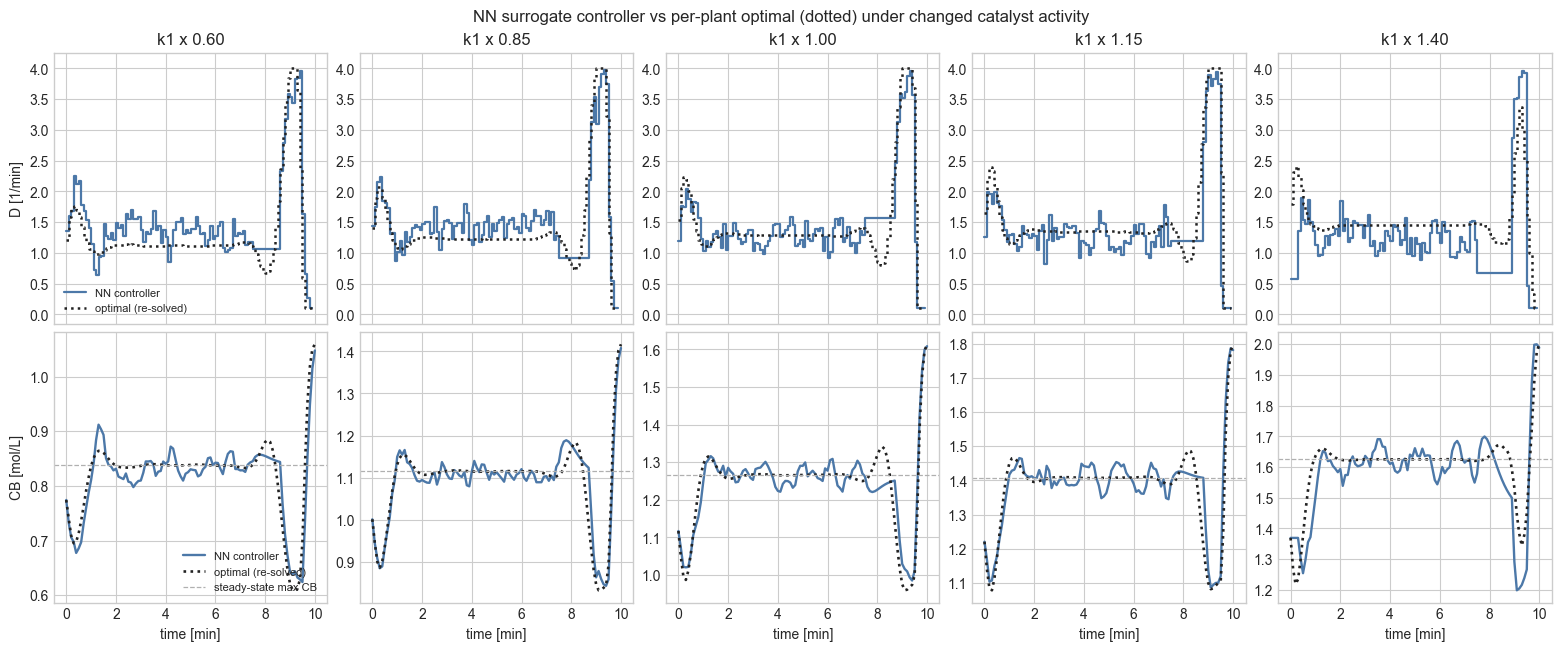

In [99]:
n_cases = len(K1_SCALES)
fig, ax = plt.subplots(2, n_cases, figsize=(3.1 * n_cases, 6.4), constrained_layout=True, sharex=True)
nn_color, opt_color = "#4c78a8", "#222222"
for c, scale in enumerate(K1_SCALES):
    res = mismatch_results[scale]
    nn_states, nn_controls, opt_case = res["nn_states"], res["nn_controls"], res["opt"]
    ctrl_times = np.arange(len(nn_controls)) * DT
    nn_times = np.arange(len(nn_states)) * DT
    ss_max = find_max_product_dilution(params=res["plant"]).cb

    ax[0, c].step(ctrl_times, nn_controls, where="post", color=nn_color, lw=1.6, label="NN controller")
    ax[0, c].step(opt_case["times"][:-1], opt_case["D"], where="post", color=opt_color, ls=":", lw=1.8, label="optimal (re-solved)")
    ax[0, c].set_title(f"k1 x {scale:.2f}")
    ax[0, c].set_ylim(D_LO - 0.25, D_HI + 0.25)

    ax[1, c].plot(nn_times, nn_states[:, CB_IDX], color=nn_color, lw=1.7, label="NN controller")
    ax[1, c].plot(opt_case["times"], opt_case["states"][:, CB_IDX], color=opt_color, ls=":", lw=1.9, label="optimal (re-solved)")
    ax[1, c].axhline(ss_max, color="#b0b0b0", ls="--", lw=0.9, label="steady-state max CB")
    ax[1, c].set_xlabel("time [min]")

ax[0, 0].set_ylabel("D [1/min]")
ax[1, 0].set_ylabel("CB [mol/L]")
ax[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
ax[1, 0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("NN surrogate controller vs per-plant optimal (dotted) under changed catalyst activity", fontsize=12)
plt.show()


### Mismatch takeaways

The table and trajectory plots compare the fixed (default-trained) NN controller against the **per-plant optimum**, re-solved by coarse-to-fine direct shooting for each changed plant and saved separately under `datasets/vdv_optimal_k1x*.npz`.

- **Moderate catalyst changes are handled near-optimally without retraining.** Across roughly +/-15% (and even +40%) on `k1`, the NN controller reaches about 99% of the optimal terminal `CB`, and the plotted `D` and `CB` trajectories nearly overlay the optimal's build-up-then-crash exit arc. This is *not* because the surrogate is accurate; it is because (1) the controller is a feedback law that re-measures the true state every 6 s and applies only the first move, and (2) scaling `k1` does not change the *shape* of the optimal strategy, so the `D*`-anchored candidate set still contains near-optimal sequences and the surrogate's *ranking* of them stays roughly right.
- **The surrogate's predictions are not robust, even when control still works.** The predicted terminal `CB` drifts from the achieved value as mismatch grows, and for a large adverse change (`k1 x 0.60`, a 40% activity drop) it is badly overconfident -- predicting around 1.28 while the plant delivers around 0.94. Here nothing load-bearing depends on that number, but on a plant with a hard constraint checked *through* the surrogate (a pressure or safety limit), this bias would be a hazard rather than a cosmetic error.
- **Large or structural changes leave performance on the table.** At `k1 x 0.60` the NN controller reaches only ~89% of the optimal terminal `CB`; the plot shows its exit arc is weaker/mistimed relative to the re-solved optimum, with no built-in warning other than the growing predicted-vs-achieved gap. The robustness above also relied on the change preserving the optimal strategy shape: a change that alters the qualitative dynamics (e.g. the inverse-response strength via `k2`/`k3`, or one that moves the optimum outside the thin training/candidate tube) would degrade faster.
- **For genuine robustness, make the kinetics a feature, not a constant.** Train the surrogate across a range of catalyst activity with that parameter as an additional input (a parametric surrogate) so it generalizes by design; or add online re-identification with periodic fine-tuning (adaptive MPC), or an offset-free output-feedback correction that learns the model error online. At minimum, monitor predicted-vs-achieved `CB` as a drift detector so silent degradation is caught.


## Takeaways

This notebook is intentionally smaller than the hydroformylation NMPC benchmark. It trains a local, **horizon-aware** output surrogate, `[CA, CB, CC, CD, D_t, ..., D_{t+P-1}, horizon_frac] -> horizon_delta_CB`, from the refined inverse-response trajectory plus perturbations around that state/control-sequence region. The receding controller fixes the current measured concentrations as equality constraints and chooses only a bounded future dilution-rate sequence by maximizing predicted end-of-horizon `CB`; only the first move is applied before the true plant is measured again.

The key correction relative to the first version of this notebook is the **shrinking horizon** plus matching terminal data coverage. A fixed `P`-step look-ahead has no terminal-time awareness, so it cannot reproduce a fixed-final-time optimal trajectory whose payoff is an end-loaded bang-bang exit arc (here: drive `D` to its max to build up `CA`, then crash `D` to its min so the accumulated reactant converts into a terminal `CB` spike that exceeds any steady-state `CB`). Shrinking `m = min(P, H - k)` as `t -> 10 min`, and training on windows for every `k` rather than only `k <= H - P`, lets the controller execute that exit arc and reach a terminal `CB` close to the reference instead of stalling with `D` pinned high.

One scope note: the horizon only shrinks within the maximum look-ahead `P`, so the controller starts anticipating the terminal time once it is within `P` steps of it. Anticipating earlier would require a longer-horizon surrogate (a larger `P`), which is a different speed/accuracy trade-off. The simplified model has no pressure variable; state and dilution-rate bounds are the active constraint checks in this notebook.
